In [1]:

%pip install transformers torch


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\AMIT\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:

import torch
import pandas as pd
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
print("Using:", "GPU" if device == 0 else "CPU")


Using: CPU


In [3]:

model_name = "dslim/bert-base-NER"

ner_pipeline = pipeline(
    "ner",
    model=model_name,
    aggregation_strategy="simple",
    device=device
)

print("BERT NER model loaded successfully!")


config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

C:\Users\AMIT\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\AMIT\.cache\huggingface\hub\models--dslim--bert-base-NER. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\AMIT\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_dow

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BERT NER model loaded successfully!


In [4]:

text = "Sundar Pichai works at Google in California."

entities = ner_pipeline(text)

for entity in entities:
    print(
        "Entity:", entity["word"],
        "| Type:", entity["entity_group"],
        "| Confidence:", round(entity["score"], 4)
    )


Entity: Sundar Pichai | Type: PER | Confidence: 0.9877
Entity: Google | Type: ORG | Confidence: 0.9987
Entity: California | Type: LOC | Confidence: 0.9996


In [5]:

entity_labels = {
    "PER": "Person",
    "ORG": "Organization",
    "LOC": "Location",
    "MISC": "Miscellaneous entity"
}

for label, meaning in entity_labels.items():
    print(f"{label}: {meaning}")


PER: Person
ORG: Organization
LOC: Location
MISC: Miscellaneous entity


In [6]:

sentences = [
    "Narendra Modi visited France.",
    "Microsoft was founded by Bill Gates and Paul Allen.",
    "Amit studies Computer Science in India.",
    "Apple announced a new product in California."
]

for sentence in sentences:
    print("\nText:", sentence)
    results = ner_pipeline(sentence)

    if results:
        for item in results:
            print(
                f"  {item['word']} -> {item['entity_group']} "
                f"({item['score']:.3f})"
            )
    else:
        print("  No entities detected.")



Text: Narendra Modi visited France.
  Na -> PER (0.999)
  ##ren -> PER (0.752)
  ##dra Modi -> PER (0.857)
  France -> LOC (1.000)

Text: Microsoft was founded by Bill Gates and Paul Allen.
  Microsoft -> ORG (0.998)
  Bill Gates -> PER (1.000)
  Paul Allen -> PER (1.000)

Text: Amit studies Computer Science in India.
  Am -> PER (0.985)
  Computer Science -> MISC (0.693)
  India -> LOC (0.999)

Text: Apple announced a new product in California.
  Apple -> ORG (0.999)
  California -> LOC (1.000)


In [7]:

records = []

for sentence in sentences:
    for entity in ner_pipeline(sentence):
        records.append({
            "Sentence": sentence,
            "Entity": entity["word"],
            "Entity Type": entity["entity_group"],
            "Confidence": round(float(entity["score"]), 4)
        })

df = pd.DataFrame(records)

if not df.empty:
    display(df)
else:
    print("No entities detected.")


,Sentence,Entity,Entity Type,Confidence
0,Narendra Modi visited France.,Na,PER,0.9994
1,Narendra Modi visited France.,##ren,PER,0.7524
2,Narendra Modi visited France.,##dra Modi,PER,0.8566
3,Narendra Modi visited France.,France,LOC,0.9998
4,Microsoft was founded by Bill Gates and Paul A...,Microsoft,ORG,0.9984
5,Microsoft was founded by Bill Gates and Paul A...,Bill Gates,PER,0.9995
6,Microsoft was founded by Bill Gates and Paul A...,Paul Allen,PER,0.9997
7,Amit studies Computer Science in India.,Am,PER,0.9850
8,Amit studies Computer Science in India.,Computer Science,MISC,0.6934
9,Amit studies Computer Science in India.,India,LOC,0.9989


In [8]:

user_text = input("Enter a sentence for NER: ")

if user_text.strip():
    results = ner_pipeline(user_text)

    print("\nDetected entities:")
    if results:
        for entity in results:
            print(
                f"{entity['word']} -> {entity['entity_group']} "
                f"(confidence: {entity['score']:.3f})"
            )
    else:
        print("No entities detected.")
else:
    print("Please enter some text.")


Enter a sentence for NER:  Microsoft was founded by Bill Gates 



Detected entities:
Microsoft -> ORG (confidence: 0.998)
Bill Gates -> PER (confidence: 1.000)


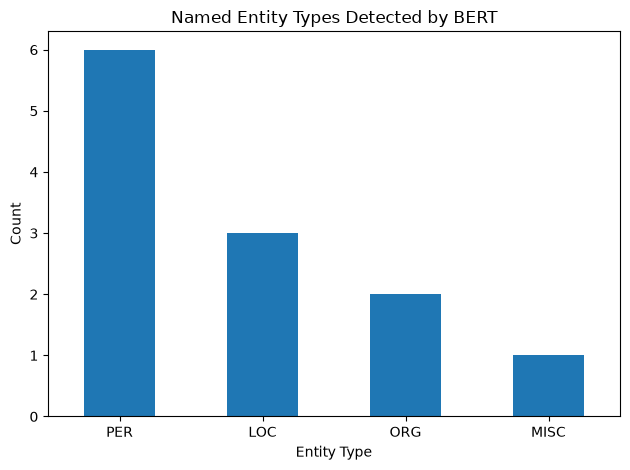

In [9]:

import matplotlib.pyplot as plt

if not df.empty:
    counts = df["Entity Type"].value_counts()

    counts.plot(kind="bar")
    plt.title("Named Entity Types Detected by BERT")
    plt.xlabel("Entity Type")
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Run the sample sentences cell first to generate results.")
